# Summative - Regression Analysis Mobile Application
## Predicting Food Prices in Sudanese Markets During the War

**Use case:** Aid agencies such as WFP give families cash to buy food. Since the war began in April 2023, prices differ sharply between markets and months. This model predicts the retail price of a food item (USD per kg) for a given market and month, to help set fair cash-transfer amounts.

# Step one: Explore and prepare the data

## 1. Imports 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
import joblib

## 2. Load the data 
Source: WFP Sudan food prices, from HDX.

In [2]:
df = pd.read_csv("wfp_food_prices_sdn.csv")
print(df.shape)
df.head()


(23384, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2001-01-15,Blue Nile,Damazin,Damazin,1026,11.79,34.36,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,46.00,17.76
1,2001-01-15,Gedaref,Al Gedaref Rural,El Gedarif,2580,14.04,35.38,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,51.67,19.95
2,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Millet,73,90 KG,actual,Wholesale,SDG,77.29,29.84
3,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,63.90,24.67
4,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Wheat,84,90 KG,actual,Wholesale,SDG,81.50,31.47


## 3. Filter to the war period
Keep prices from 15 April 2023 onward and remove the exchange-rate rows, which are not food.

In [3]:
df["date"] = pd.to_datetime(df["date"])
war = df[df["date"] >= "2023-04-15"].copy()
war = war[war["category"] != "non-food"]
print(len(war))

6961


## 4. Price per kg
Some prices are for 3 KG or 3.5 KG bags, so every price is divided by its weight. Oil is sold per litre and stays per litre.

In [4]:
def kg_in_unit(unit):
    if unit in ("KG", "L"):
        return 1.0
    return float(unit.split()[0])

war["usd_per_kg"] = war["usdprice"] / war["unit"].apply(kg_in_unit)
war["year"] = war["date"].dt.year
war["month"] = war["date"].dt.month
war[["commodity", "unit", "usdprice", "usd_per_kg"]].head()

,commodity,unit,usdprice,usd_per_kg
16383,Millet,3.5 KG,3.85,1.100000
16384,Sorghum,3 KG,3.10,1.033333
16385,Wheat flour,KG,1.72,1.720000
16386,Meat (beef),KG,5.02,5.020000
16387,Meat (goat),KG,8.21,8.210000


## 5. Dataset overview
The war period data has 6,961 rows and 9 features mixing categorical and numeric data.

In [5]:
categorical = ["market", "admin1", "category", "commodity", "pricetype"]
numeric = ["latitude", "longitude", "year", "month"]
print("Rows:", len(war))
print("Categorical features:", len(categorical), categorical)
print("Numeric features:", len(numeric), numeric)

Rows: 6961
Categorical features: 5 ['market', 'admin1', 'category', 'commodity', 'pricetype']
Numeric features: 4 ['latitude', 'longitude', 'year', 'month']


## 6. Correlation heatmap

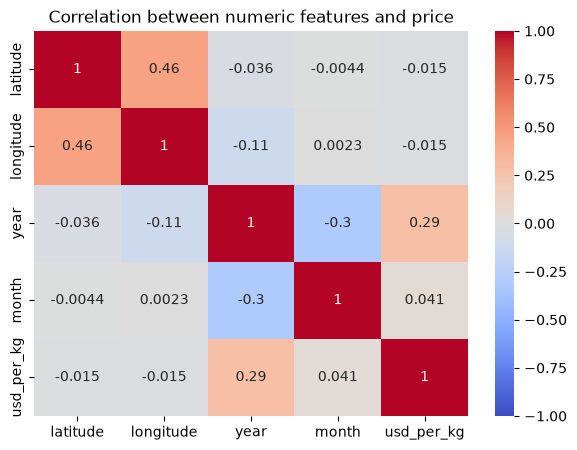

In [6]:
corr = war[["latitude", "longitude", "year", "month", "usd_per_kg"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric features and price")
plt.show()

### Explanation
Year has the strongest link to price (0.29), because prices kept rising during the war. Latitude, longitude and month are almost unrelated to price on their own, so price must depend mostly on the categorical features like commodity and market. No two features are strongly correlated (the highest is 0.46), so I keep all of them. Year will be my x-axis for the scatter plots later, because it's the feature most correlated with price.

## 7. Distribution of the target

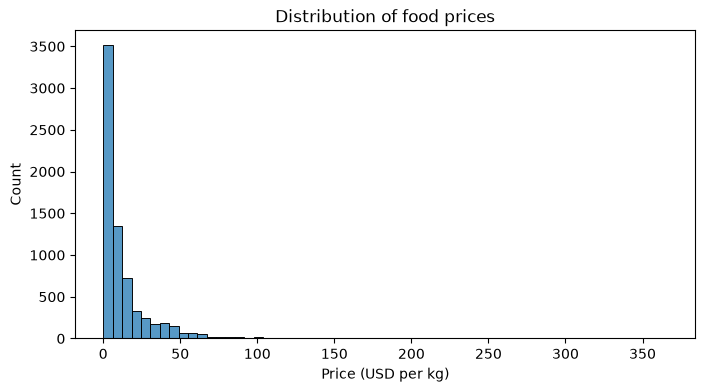

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(war["usd_per_kg"], bins=60)
plt.xlabel("Price (USD per kg)")
plt.title("Distribution of food prices")
plt.show()

### Explanation
Most prices are below $15 per kg, but there is a long tail of extreme prices up to $366, almost all from Al Fashir and Kadugli during their sieges in 2025. These prices are real, not errors, and they are the markets where aid matters most, so I kept them. I expect the linear models to struggle with these extremes and the tree-based models to handle them better.

## 8. Price by food

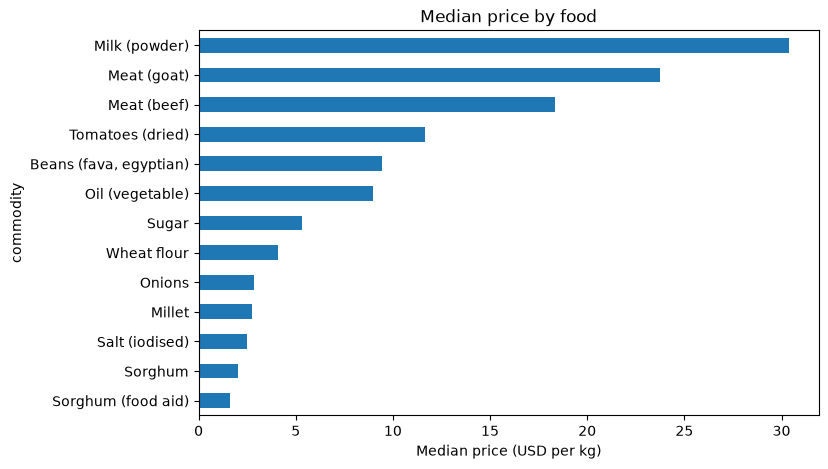

In [8]:
order = war.groupby("commodity")["usd_per_kg"].median().sort_values()
plt.figure(figsize=(8, 5))
order.plot(kind="barh")
plt.xlabel("Median price (USD per kg)")
plt.title("Median price by food")
plt.show()

### Explanation
The type of food changes the price far more than any numeric feature: the median ranges from $1.61 for food-aid sorghum to $30.39 for powdered milk. This shows commodity is the most important feature, so I make sure to keep it and encode it properly.

## 9. Dropping columns
| Dropped | Why |
| --- | --- |
| price | The same price in SDG; keeping it would leak the answer |
| usdprice | The target is calculated from it, so keeping it would leak the answer |
| date | Replaced by year and month |
| unit | Only needed to calculate the price per kg |
| currency | Always SDG, so it teaches nothing |
| priceflag | Always "actual", so it teaches nothing |
| admin2 | Each market has exactly one admin2, so it repeats the market |
| market_id, commodity_id | ID numbers that repeat market and commodity |

pricetype is always "Retail" in the war period; I keep it on my teacher's advice.

In [9]:
dropped = ["price", "usdprice", "date", "unit", "currency", "priceflag", "admin2", "market_id", "commodity_id"]
data = war.drop(columns=dropped)
X = data.drop(columns="usd_per_kg")
y = data["usd_per_kg"]
print(X.shape, y.shape)
X.head()

(6961, 9) (6961,)


,admin1,market,latitude,longitude,category,commodity,pricetype,year,month
16383,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Millet,Retail,2023,4
16384,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Sorghum,Retail,2023,4
16385,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Wheat flour,Retail,2023,4
16386,Blue Nile,Damazin,11.79,34.36,"meat, fish and eggs",Meat (beef),Retail,2023,4
16387,Blue Nile,Damazin,11.79,34.36,"meat, fish and eggs",Meat (goat),Retail,2023,4


## 10. Most important features

- commodity: the type of food changes the median price from $1.61 to $30.39 
- year: the numeric feature most linked to price (0.29), because prices rose through the war
- market and admin1: the extreme prices come from specific besieged markets (Al Fashir, Kadugli), so location matters 

## 11. Train/test split
80% of the rows are used for training and 20% are kept aside as unseen test data.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(5568, 9) (1393, 9)


## 12. Encoding and scaling
Categorical columns are one-hot encoded and numeric columns are standardized. Both are fitted on the training set only, so no information from the test set leaks into training.

In [11]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("num", StandardScaler(), numeric),
])
X_train_ready = preprocess.fit_transform(X_train)
X_test_ready = preprocess.transform(X_test)
print(X_train_ready.shape, X_test_ready.shape)

(5568, 62) (1393, 62)


# Step two: Train and compare four models

## 13. Linear regression with gradient descent (SGDRegressor)
SGDRegressor is trained one epoch at a time with partial_fit, recording the train and test MSE after each epoch.

In [12]:
def train_sgd(eta0, alpha, epochs):
    model = SGDRegressor(eta0=eta0, alpha=alpha, learning_rate="constant", random_state=42)
    train_loss, test_loss = [], []
    for epoch in range(epochs):
        model.partial_fit(X_train_ready, y_train)
        train_loss.append(mean_squared_error(y_train, model.predict(X_train_ready)))
        test_loss.append(mean_squared_error(y_test, model.predict(X_test_ready)))
    return model, train_loss, test_loss

## 14. Tuning SGDRegressor
Trying 4 learning rates and 3 alpha values, each for 100 epochs, and record the test MSE after 10, 50 and 100 epochs.

In [ ]:
results = []
for eta0 in [0.0001, 0.001, 0.01, 0.1]:
    for alpha in [0.0001, 0.01, 1.0]:
        model, train_loss, test_loss = train_sgd(eta0, alpha, 100)
        for epochs in [10, 50, 100]:
            results.append({"eta0": eta0, "alpha": alpha, "epochs": epochs, "test_mse": test_loss[epochs - 1]})

tuning = pd.DataFrame(results).sort_values("test_mse")
tuning

### Tuning results
The best setting was a learning rate of 0.001 with alpha 0.0001, giving a test MSE of 205.74 after 100 epochs. A smaller learning rate (0.0001) learned too slowly: its test MSE was about 228 after 10 epochs and only reached 206.71 after 100. Larger learning rates took steps that were too big and settled at a worse loss (about 210 for 0.01 and about 270 for 0.1). Alpha 0.0001 and 0.01 gave almost the same result, but alpha 1.0 penalised the model too much and pushed the test MSE above 300. More epochs only helped with small learning rates; at 0.001 the loss barely changed after epoch 10 (206.69 at 10, 205.74 at 100).

## 15. Loss curve

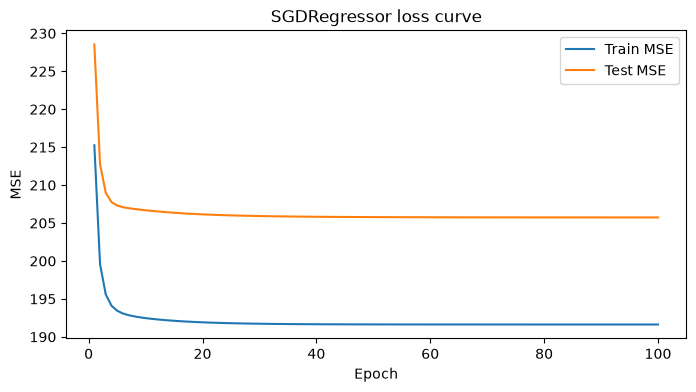

In [ ]:
best = tuning.iloc[0]
sgd, train_loss, test_loss = train_sgd(best["eta0"], best["alpha"], int(best["epochs"]))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(train_loss) + 1), train_loss, label="Train MSE")
plt.plot(range(1, len(test_loss) + 1), test_loss, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

### Explanation
Both losses drop quickly in the first few epochs (test MSE goes from 228.5 at epoch 1 to 207.1 at epoch 6) and then flatten, ending at 191.6 for train and 205.7 for test. Since the curve is flat, more epochs would not help. The gap between train and test is small, so the model is not overfitting. The loss stays high because a straight line cannot capture price combinations such as a type of food in a besieged market.

## 16. Linear regression (closed form), Decision Tree and Random Forest

In [ ]:
lin = LinearRegression()
lin.fit(X_train_ready, y_train)

tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train_ready, y_train)

forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forest.fit(X_train_ready, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 17. Model comparison
All four models are evaluated on the same test set using MSE. Lower is better.

In [ ]:
models = {"SGDRegressor": sgd, "LinearRegression": lin, "Decision Tree": tree, "Random Forest": forest}

rows = []
for name, model in models.items():
    rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, model.predict(X_train_ready)),
        "Test MSE": mean_squared_error(y_test, model.predict(X_test_ready)),
    })

comparison = pd.DataFrame(rows).sort_values("Test MSE")
comparison.round(2)

,Model,Train MSE,Test MSE
3,Random Forest,6.49,45.65
2,Decision Tree,0.00,48.66
0,SGDRegressor,191.63,205.74
1,LinearRegression,191.25,205.84


### Best model
The best model is Random Forest, with the lowest test MSE (about 45.7). I use test MSE as the criterion because it measures how well a model predicts prices it has never seen. The linear models had a test MSE around 206 because a straight line cannot capture combinations like food type × besieged market. The single decision tree memorised the training data (train MSE 0) and did worse on new data, while the forest averages 100 trees, which reduces that overfitting.

## 18. Scatter plot before training
Year is the feature most correlated with price, so it is used on the x-axis.

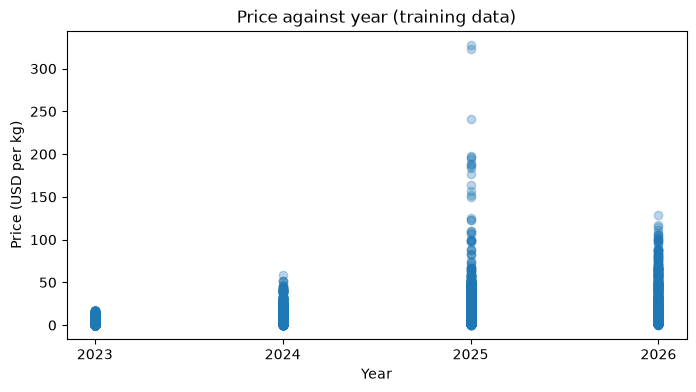

In [ ]:
plt.figure(figsize=(8, 4))
plt.scatter(X_train["year"], y_train, alpha=0.3)
plt.xlabel("Year")
plt.ylabel("Price (USD per kg)")
plt.title("Price against year (training data)")
plt.xticks([2023, 2024, 2025, 2026])
plt.show()

## 19. Scatter plot after training, with the fitted line
A one-feature linear regression (year only) is fitted just for this plot.

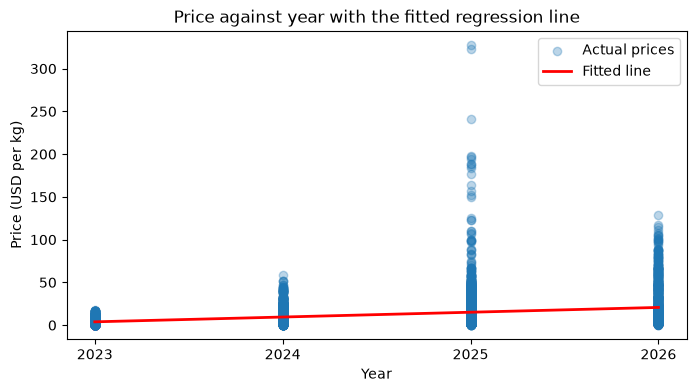

Slope: 5.61 USD per kg per year


In [ ]:
line = LinearRegression()
line.fit(X_train[["year"]], y_train)

years = pd.DataFrame({"year": [2023, 2026]})

plt.figure(figsize=(8, 4))
plt.scatter(X_train["year"], y_train, alpha=0.3, label="Actual prices")
plt.plot(years["year"], line.predict(years), color="red", linewidth=2, label="Fitted line")
plt.xlabel("Year")
plt.ylabel("Price (USD per kg)")
plt.title("Price against year with the fitted regression line")
plt.xticks([2023, 2024, 2025, 2026])
plt.legend()
plt.show()

print("Slope:", round(line.coef_[0], 2), "USD per kg per year")

### Explanation
The fitted line rises by about $5.61 per kg each year, showing prices went up through the war. But the dots are spread far from the line in every year, because year alone cannot explain price; the type of food and the market matter much more. This is why the full linear models still had a high MSE and the tree models did better.

## 20. Saving the best model & predict
The model with the lowest test MSE is saved together with its preprocessing as one pipeline.


In [ ]:
best_name = comparison.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

best_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", best_model),
])

print("Pipeline test MSE:", round(mean_squared_error(y_test, best_pipeline.predict(X_test)), 2))

joblib.dump(best_pipeline, "../API/best_model.pkl", compress=3)

Best model: Random Forest
Pipeline test MSE: 45.65


['../API/best_model.pkl']

## 21. Predicting one row of the test set
This function loads the saved model and predicts the price for one row. The API reuses it.

In [ ]:
def predict_price(row):
    model = joblib.load("../API/best_model.pkl")
    return model.predict(row)[0]

row = X_test.iloc[[0]]
print(row.to_dict("records")[0])
print("Predicted price:", round(predict_price(row), 2), "USD per kg")
print("Actual price:   ", round(y_test.iloc[0], 2), "USD per kg")

{'admin1': 'Blue Nile', 'market': 'Damazin', 'latitude': 11.79, 'longitude': 34.36, 'category': 'cereals and tubers', 'commodity': 'Sorghum', 'pricetype': 'Retail', 'year': 2024, 'month': 3}
Predicted price: 1.01 USD per kg
Actual price:    0.8 USD per kg
